In [3]:
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
# get noaa dataset
noaa_df = pd.read_csv(r"C:\Users\katel\extreme climate\data\temp_precip\temp_precip.csv")

In [6]:
noaa_df['NAME'].drop_duplicates()

0                   EAGLE CO AIRPORT, CO US
16836                     DILLON 1 E, CO US
44775               GRAND LAKE 6 SSW, CO US
72585    GRAND JUNCTION WALKER FIELD, CO US
Name: NAME, dtype: object

In [5]:
# filter columns
noaa_df = noaa_df[['STATION','NAME','ELEVATION', 'DATE', 'TMAX','TMIN','PRCP']]

In [6]:
noaa_df = noaa_df.rename(columns={'STATION':'station'
                        ,'NAME': 'name'
                        ,'ELEVATION': 'elevation'
                        , 'DATE': 'date'
                        , 'TMAX': 'temp_max'
                        ,'TMIN': 'temp_min'
                        ,'PRCP': 'precipitation'})

In [7]:
noaa_df.describe()

,elevation,temp_max,temp_min,precipitation
count,100616.000000,100543.000000,100529.000000,99798.000000
mean,2207.996534,57.168953,27.233167,0.033033
std,524.774955,20.586523,18.723096,0.095861
min,1470.400000,-10.000000,-51.000000,0.000000
25%,1470.400000,40.000000,15.000000,0.000000
50%,2526.800000,58.000000,28.000000,0.000000
75%,2767.900000,74.000000,39.000000,0.010000
max,2767.900000,107.000000,80.000000,6.050000


In [8]:
# convert dates
noaa_df['date'] = pd.to_datetime(noaa_df['date'])
noaa_df['month_num'] =  noaa_df['date'].dt.month

In [9]:
# Limit to 1990-present
recent_noaa = noaa_df[
    noaa_df['date'] >= '1990-01-01'
].copy()

recent_noaa = recent_noaa.sort_values(['name', 'date'])

In [11]:
# monthly station values
noaa_monthly = (
    recent_noaa
    .set_index('date')
    .groupby('name')
    .resample('MS')
    .agg({
        'temp_max': 'mean',
        'temp_min': 'mean',
        'precipitation': 'sum'
    })
    .reset_index()
)

noaa_monthly['month_num'] = noaa_monthly['date'].dt.month

In [12]:
noaa_monthly[:5]

,name,date,temp_max,temp_min,precipitation,month_num
0,"DILLON 1 E, CO US",1990-01-01,31.709677,1.032258,0.38,1
1,"DILLON 1 E, CO US",1990-02-01,34.142857,4.607143,0.36,2
2,"DILLON 1 E, CO US",1990-03-01,41.451613,15.548387,1.39,3
3,"DILLON 1 E, CO US",1990-04-01,48.300000,22.200000,1.65,4
4,"DILLON 1 E, CO US",1990-05-01,54.516129,25.741935,0.81,5


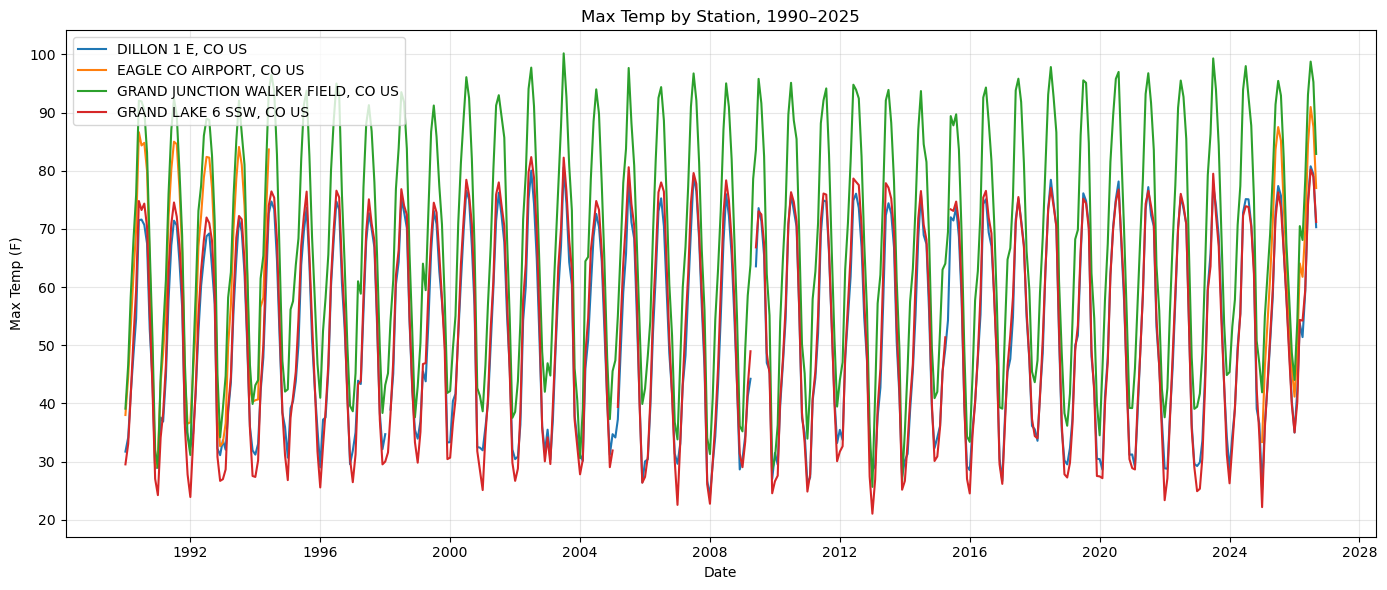

In [15]:
# Plot max temp by station
plt.figure(figsize=(14, 6))
for station, group in noaa_monthly.groupby('name'):
    plt.plot(
        group['date'],
        group['temp_max'],
        label=station
    )

plt.xlabel('Date')
plt.ylabel('Max Temp (F)')
plt.title('Max Temp by Station, 1990–2025')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

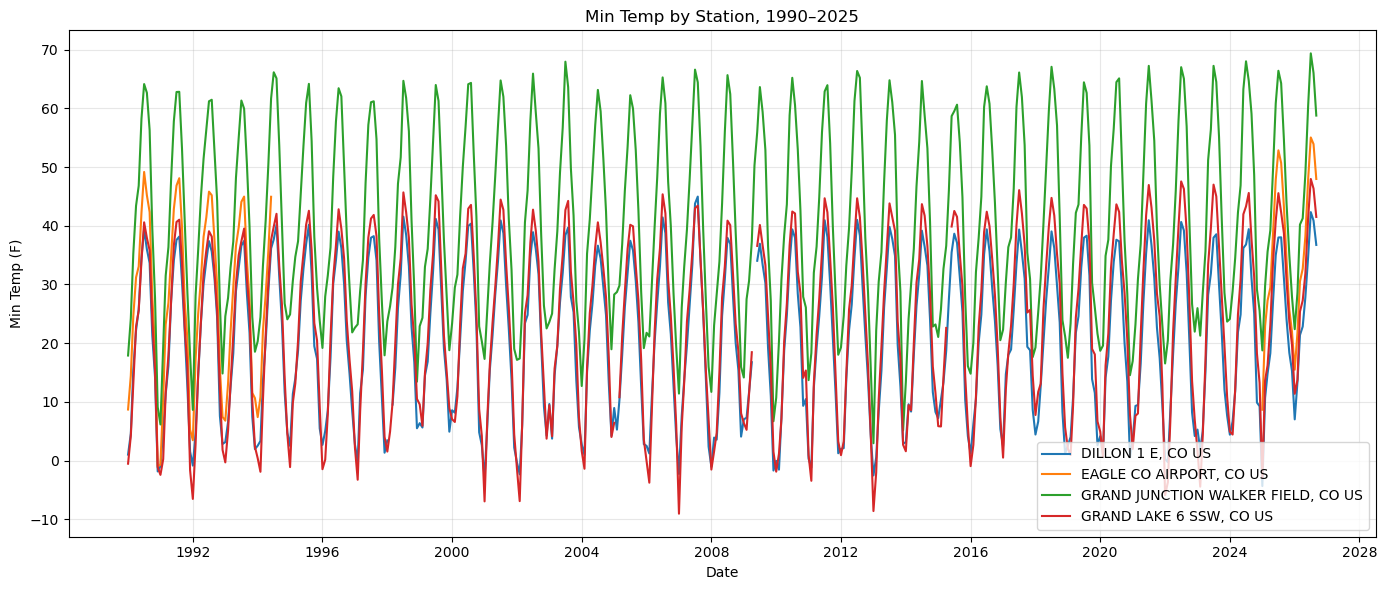

In [16]:
# Plot min temp by station
plt.figure(figsize=(14, 6))
for station, group in noaa_monthly.groupby('name'):
    plt.plot(
        group['date'],
        group['temp_min'],
        label=station
    )

plt.xlabel('Date')
plt.ylabel('Min Temp (F)')
plt.title('Min Temp by Station, 1990–2025')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
# Daily dataset
noaa_df.to_parquet(
    r"C:\Users\katel\extreme climate\data\temp_precip_daily.parquet",
    index=False
)

# Monthly dataset
noaa_monthly.to_parquet(
    r"C:\Users\katel\extreme climate\data\temp_precip_monthly.parquet",
    index=False
)